# EDA unificado: sistema de recomendación para clientes sin historial (cold start)
## Muestra p10 del dataset H&M Personalized Fashion Recommendations · Lookwise Data Lab · Sprint 1

Versión unificada de los EDA individuales de Flor e Isa (se sube como notebook aparte, sin modificar el individual de Isa): conserva una estructura común (calidad, tiempo, precio, clientes, artículos, cruces, corte y fríos) y el análisis variable por variable de los clientes, con las definiciones y limitaciones contrastadas con la documentación del dataset.

---

## Índice

[Contexto de negocio y objetivo](#contexto)

1. [Librerías y carga](#s1)
2. [Diccionario de variables](#s2)

**Parte 1. Calidad de datos (tablas completas)**

3. [Transacciones](#s3)
4. [Clientes](#s4)
5. [Artículos](#s5)
6. [Integridad entre tablas](#s6)
7. [Corte train/test](#s7)

**Parte 2. Exploración con train**

8. [Evolución temporal](#s8)
9. [Estacionalidad y hemisferio](#s9)
10. [Precio por tipo de producto](#s10)
11. [Duplicados por grupo de producto](#s11)
12. [Compras por cliente](#s12)
13. [Artículos y cola larga](#s13)
14. [Edad y mix de compra](#s14)
15. [Clientes fríos y cobertura de artículos](#s15)

[Hallazgos, decisiones y limitaciones](#s16)

<a id="contexto"></a>
## Contexto de negocio y objetivo

H&M, multinacional sueca de moda, prevé abrir su primera tienda en Argentina en 2027 (a través de su franquiciado Hola Moda). Como escenario del caso, planteamos que la apertura estará acompañada por el lanzamiento de su tienda online. Sin clientes ni compras locales, el sitio no puede personalizar la experiencia de sus primeros visitantes (*cold start*). Como equipo consultor, diseñamos un sistema de recomendación para ese lanzamiento.

- **Módulo 1 (principal):** ranking de 12 productos para clientes nuevos o con poco historial, evaluado frente al baseline de popularidad con MAP@12, Precision@12 y Recall@12 sobre clientes simulados como "fríos".
- **Módulo 2 (posible extensión):** productos complementarios ("Completá el look"), con métricas propias (por ejemplo, HitRate@12), cobertura y diversidad del catálogo.

**Objetivo de este EDA:** entender la estructura y la calidad de los datos, detectar riesgos (*data leakage*, sesgos, limitaciones del dataset) y dejar listas las decisiones que se toman con el grupo: corte train/test, tratamiento de faltantes y duplicados y método para simular clientes fríos.

**Principios metodológicos**
- Todas las cifras se calculan en las celdas; ninguna se escribe a mano.
- La calidad de los datos se revisa con las tablas completas de la muestra. Lo que sirve para decidir algo (estacionalidad, popularidad, perfil de clientes) se calcula **solo con train**, para evitar *data leakage*.
- Se distingue lo que es dato, lo que es inferencia respaldada por los datos y lo que es hipótesis sin confirmar.
- El EDA diagnostica: no modifica ni elimina datos. El tratamiento es una decisión del grupo.

**Muestra:** p10 (10% de los clientes, elegidos con un hash determinístico de `customer_id`), solo canal online y con todo el historial de cada cliente elegido. En el notebook las tablas se llaman `trans`, `cust` y `art`.

<a id="s1"></a>
## 1. Librerías y carga

Se usan `pandas` y `matplotlib`. Los datos se leen de los archivos Parquet de la carpeta `p10`; `customer_id` y `article_id` son texto (el segundo conserva los ceros iniciales) y `t_dat` se convierte a fecha.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 40
pd.options.display.max_colwidth = 90
pd.options.display.width = 200
plt.rcParams["figure.dpi"] = 100
AZUL, ROJO = "#2E86AB", "#E63946"

In [2]:
ruta_base = "../dataset"   # carpeta dataset/ local (los datos no se suben al repo: ver docs/dataset_README.md)
base = f"{ruta_base}/p10"

trans = pd.read_parquet(f"{base}/transactions.parquet")
cust = pd.read_parquet(f"{base}/customers.parquet")
art = pd.read_parquet(f"{base}/articles.parquet")
trans["t_dat"] = pd.to_datetime(trans["t_dat"])

for nombre, t in [("trans", trans), ("cust", cust), ("art", art)]:
    print(f"{nombre:6s}: {t.shape[0]:>10,} filas x {t.shape[1]:>2} columnas")

trans :  2,226,486 filas x  5 columnas
cust  :    110,252 filas x  7 columnas
art   :    105,542 filas x 25 columnas


In [ ]:
#chequeo de ruta si es existente

from pathlib import Path

base = Path("../dataset/p10")

print("Dataset exists:", base.exists())
print("Transactions exists:", (base / "transactions.parquet").exists())

Dataset exists: True
Transactions exists: True


<a id="s2"></a>
## 2. Diccionario de variables

La columna **fuente** dice de dónde sale cada definición: *Documentación* es la documentación disponible del dataset (comentarios del proveedor de los datos, fuente de segunda mano; ver `docs/dataset_README.md`, sección "Fuentes y referencias"); *por el nombre* es una interpretación a verificar contra la documentación oficial del dataset. El precio está escalado: **no representa dinero real**.

In [3]:
diccionario = pd.DataFrame([
    ("trans", "t_dat", "Fecha de la compra (sin hora)", "dato"),
    ("trans", "customer_id", "Identificador anónimo del cliente (hash de 64 caracteres)", "dato"),
    ("trans", "article_id", "Identificador del artículo (10 dígitos, sin talle)", "dato"),
    ("trans", "price", "Precio pagado, escalado, sin unidad", "Documentación"),
    ("trans", "sales_channel_id", "Canal de venta: 1 = tienda, 2 = online", "Documentación + datos"),
    ("cust", "FN", "Recibe el newsletter de moda (Fashion News)", "Documentación"),
    ("cust", "Active", "Activo para comunicaciones", "Documentación"),
    ("cust", "club_member_status", "Estado como socio del club (ACTIVE, PRE-CREATE, LEFT CLUB)", "por el nombre"),
    ("cust", "fashion_news_frequency", "Frecuencia del newsletter (NONE, Regularly, Monthly)", "por el nombre"),
    ("cust", "age", "Edad del cliente", "por el nombre"),
    ("cust", "postal_code", "Código postal anonimizado (hash): no se interpreta como ubicación", "por el nombre"),
    ("art", "article_id / product_code", "Id del artículo / código del producto (primeros 7 dígitos del id; agrupa variantes)", "por el nombre"),
    ("art", "product_type / product_group", "Tipo y grupo de producto (códigos _no y nombres _name)", "por el nombre"),
    ("art", "graphical_appearance, colour_group, perceived_colour_*", "Aspecto gráfico y color (código y nombre)", "por el nombre"),
    ("art", "department, section, index, index_group, garment_group", "Jerarquías del catálogo (código y nombre)", "por el nombre"),
    ("art", "detail_desc", "Descripción en texto del artículo", "por el nombre"),
], columns=["tabla", "variable", "qué es", "fuente"])
display(diccionario)

,tabla,variable,qué es,fuente
0,trans,t_dat,Fecha de la compra (sin hora),dato
1,trans,customer_id,Identificador anónimo del cliente (hash de 64 caracteres),dato
2,trans,article_id,"Identificador del artículo (10 dígitos, sin talle)",dato
3,trans,price,"Precio pagado, escalado, sin unidad",Documentación
4,trans,sales_channel_id,"Canal de venta: 1 = tienda, 2 = online",Documentación + datos
5,cust,FN,Recibe el newsletter de moda (Fashion News),Documentación
6,cust,Active,Activo para comunicaciones,Documentación
7,cust,club_member_status,"Estado como socio del club (ACTIVE, PRE-CREATE, LEFT CLUB)",por el nombre
8,cust,fashion_news_frequency,"Frecuencia del newsletter (NONE, Regularly, Monthly)",por el nombre
9,cust,age,Edad del cliente,por el nombre


La documentación del dataset respalda: canal 1 = tienda y 2 = online; el precio no revela valores reales; la tabla de transacciones incluye también compras que luego se devolvieron; se permite recomendar artículos ya comprados; el mercado de origen no se revela. Para `PRE-CREATE` no encontramos definición.

# PARTE 1. Calidad de datos (tablas completas de la muestra)

<a id="s3"></a>
## 3. Transacciones (`trans`)

Cada fila es la compra de un artículo por un cliente en una fecha. Se revisan estructura y nulos, canal de venta, fechas, precio y duplicados.

### 3.1 Estructura, nulos y tipos

In [4]:
trans.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2226486 entries, 0 to 2226485
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   t_dat             2226486 non-null  datetime64[ns]
 1   customer_id       2226486 non-null  object        
 2   article_id        2226486 non-null  object        
 3   price             2226486 non-null  float64       
 4   sales_channel_id  2226486 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 84.9+ MB


**Conclusión:** `trans` tiene 2.226.486 filas y 5 columnas, **sin nulos**. `t_dat` llega como texto y se convierte a fecha; `customer_id` (64 caracteres) y `article_id` (10 caracteres, con ceros iniciales) se mantienen como texto para no perder información ni romper los cruces; `price` es decimal.

### 3.2 Canal de venta

In [5]:
print(trans["sales_channel_id"].value_counts())

sales_channel_id
2    2226486
Name: count, dtype: int64


**Conclusión:** `sales_channel_id` vale siempre 2 (online) porque la muestra se restringió a ese canal. Es una constante: no aporta información y no se usa. Que 2 = online lo respaldan la documentación del dataset y los datos (abril de 2020, cuando las tiendas físicas estaban cerradas, hay ventas con canal 2).

### 3.3 Fechas

In [6]:
print("Primera fecha:", trans["t_dat"].min().date(), "| última:", trans["t_dat"].max().date())
dias_cal = (trans["t_dat"].max() - trans["t_dat"].min()).days + 1
print("Días de calendario:", dias_cal, "| días con compras:", trans["t_dat"].nunique())
print("¿Alguna fecha con hora?:", (trans["t_dat"] != trans["t_dat"].dt.normalize()).any())
diario = trans.groupby("t_dat").size()
print(f"Compras por día: mediana {diario.median():,.0f} | promedio {diario.mean():,.0f} | máximo {diario.max():,} ({diario.idxmax().date()})")

Primera fecha: 2018-09-20 | última: 2020-09-22
Días de calendario: 734 | días con compras: 734
¿Alguna fecha con hora?: False
Compras por día: mediana 2,752 | promedio 3,033 | máximo 16,104 (2020-04-11)


**Conclusión:** los datos van del 20/9/2018 al 22/9/2020: 734 días de calendario y 734 con compras, **sin huecos**. La fecha no tiene hora, así que no se puede ordenar las compras dentro de un mismo día.

### 3.4 Precio

In [7]:
cuantiles = trans["price"].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1.0])
cuantiles.index = [f"{p:.1%}" for p in cuantiles.index]
display(cuantiles.to_frame("price"))
print("Precios <= 0:", (trans["price"] <= 0).sum())

,price
1.0%,0.0051
5.0%,0.0085
25.0%,0.0169
50.0%,0.0254
75.0%,0.0339
90.0%,0.0508
99.0%,0.1017
99.9%,0.1749
100.0%,0.5068


Precios <= 0: 0


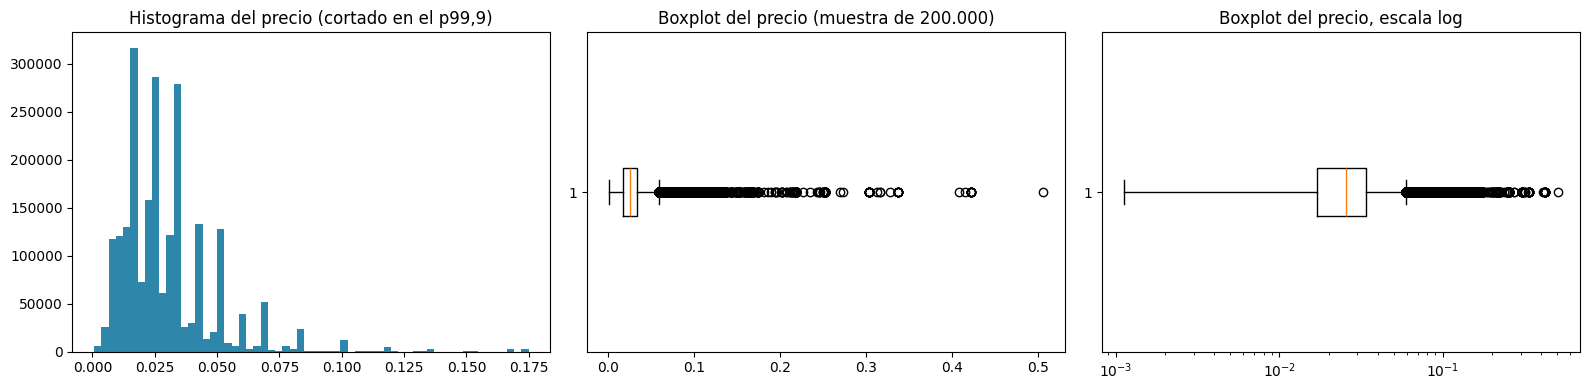

In [8]:
muestra = trans["price"].sample(200_000, random_state=42)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(trans["price"].clip(upper=trans["price"].quantile(0.999)), bins=60, color=AZUL)
ax[0].set_title("Histograma del precio (cortado en el p99,9)")
ax[1].boxplot(muestra, vert=False)
ax[1].set_title("Boxplot del precio (muestra de 200.000)")
ax[2].boxplot(muestra, vert=False)
ax[2].set_xscale("log")
ax[2].set_title("Boxplot del precio, escala log")
plt.tight_layout()
plt.show()

**Conclusión:** mediana 0,0254; p90 0,0508; p99 0,1017; p99,9 0,1749; máximo 0,5068. No hay precios cero ni negativos. La cola derecha es larga pero **gradual**, sin saltos bruscos, y el boxplot marca muchos puntos por encima del bigote justamente por esa cola. El precio no tiene unidad, así que solo sirve para comparar. **No se elimina nada.** En la Parte 2 se ve a qué productos corresponde la cola alta (abrigos y camperas).

### 3.5 Duplicados

In [9]:
n = len(trans)
dup_total = trans.duplicated().sum()
dup_sin_precio = trans.duplicated(subset=["t_dat", "customer_id", "article_id"]).sum()
print(f"Filas completamente repetidas: {dup_total:,} ({dup_total / n:.2%})")
print(f"Repetidas ignorando el precio: {dup_sin_precio:,} ({dup_sin_precio / n:.2%})")
print(f"Diferencia (mismo cliente, artículo y día, con precio distinto): {dup_sin_precio - dup_total:,}")

Filas completamente repetidas: 266,398 (11.96%)
Repetidas ignorando el precio: 284,045 (12.76%)
Diferencia (mismo cliente, artículo y día, con precio distinto): 17,647


**Conclusión:** hay 266.398 filas completamente repetidas (11,96%) y 284.045 si se ignora el precio; la diferencia (unas 17.600) son compras del mismo artículo, cliente y día con **precio distinto**. Según la documentación del dataset, la tabla incluye devoluciones, y el dataset no tiene talle ni cantidad. Las explicaciones posibles son varias unidades de lo mismo, el mismo artículo en distintos talles o una compra y su devolución, pero **no se puede confirmar cuál**. Se conservan; la sección 11 mira dónde se concentran.

<a id="s4"></a>
## 4. Clientes (`cust`), variable por variable

Una fila por cliente. Cada variable se analiza con el mismo esquema: qué es, valores y vacíos, consistencia con otras variables, utilidad para el proyecto y decisión (conservar, usar o descartar). Recordar que `cust` es una foto de un solo momento.

### 4.1 Estructura y nulos

In [10]:
cust.info(show_counts=True)
nulos = cust.isna().sum().to_frame("nulos")
nulos["%"] = (nulos["nulos"] / len(cust) * 100).round(2)
display(nulos)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110252 entries, 0 to 110251
Data columns (total 7 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   customer_id             110252 non-null  object 
 1   FN                      37225 non-null   float64
 2   Active                  36407 non-null   float64
 3   club_member_status      109651 non-null  object 
 4   fashion_news_frequency  109048 non-null  object 
 5   age                     109044 non-null  float64
 6   postal_code             110252 non-null  object 
dtypes: float64(3), object(4)
memory usage: 5.9+ MB


,nulos,%
customer_id,0,0.0000
FN,73027,66.2400
Active,73845,66.9800
club_member_status,601,0.5500
fashion_news_frequency,1204,1.0900
age,1208,1.1000
postal_code,0,0.0000


**Conclusión:** `cust` tiene 110.252 filas (una por cliente) y 7 columnas. Nulos: `FN` 66,24%, `Active` 66,98%, `age` 1,10% (1.208), `fashion_news_frequency` 1,09% (1.204) y `club_member_status` 0,55% (601). `customer_id` y `postal_code` están completos. Es una **foto de un solo momento**: no hay fecha de registro de cada valor (ver limitaciones).

### 4.2 `FN`

In [11]:
cruce_fn = pd.crosstab(cust["FN"].fillna(0), cust["fashion_news_frequency"].fillna("(vacío)"), margins=True)
cruce_fn = cruce_fn.rename(index={0.0: "FN vacío", 1.0: "FN = 1"})
display(cruce_fn)
display((pd.crosstab(cust["FN"].fillna(0), cust["fashion_news_frequency"].fillna("(vacío)"), normalize="index") * 100).round(1).rename(index={0.0: "FN vacío", 1.0: "FN = 1"}))

fashion_news_frequency,(vacío),Monthly,NONE,Regularly,All
FN,,,,,
FN vacío,1204,0,71664,159,73027
FN = 1,0,46,45,37134,37225
All,1204,46,71709,37293,110252


fashion_news_frequency,(vacío),Monthly,NONE,Regularly
FN,,,,
FN vacío,1.6000,0.0000,98.1000,0.2000
FN = 1,0.0000,0.1000,0.1000,99.8000


**Conclusión de `FN`:** 66,24% de vacíos (73.027 de 110.252). Cruzada con `fashion_news_frequency`, el 99,8% de los `FN = 1` es `Regularly` y el 98,1% de los vacíos es `NONE`: el vacío equivale casi siempre a "no recibe el newsletter" (inferencia respaldada por los datos, no documentada). Solo 204 clientes (0,2%) no coinciden. Es redundante con `fashion_news_frequency`: **se conserva pero no se usa**.

### 4.3 `Active`

In [12]:
display(pd.crosstab(cust["Active"].fillna(0), cust["club_member_status"].fillna("(vacío)"), margins=True).rename(index={0.0: "Active vacío", 1.0: "Active = 1"}))
display((pd.crosstab(cust["Active"].fillna(0), cust["club_member_status"].fillna("(vacío)"), normalize="index") * 100).round(1).rename(index={0.0: "Active vacío", 1.0: "Active = 1"}))

club_member_status,(vacío),ACTIVE,LEFT CLUB,PRE-CREATE,All
Active,,,,,
Active vacío,567,64556,53,8669,73845
Active = 1,34,35825,0,548,36407
All,601,100381,53,9217,110252


club_member_status,(vacío),ACTIVE,LEFT CLUB,PRE-CREATE
Active,,,,
Active vacío,0.8000,87.4000,0.1000,11.7000
Active = 1,0.1000,98.4000,0.0000,1.5000


**Conclusión de `Active`:** 66,98% de vacíos (73.845). El 98,4% de los `Active = 1` es socio ACTIVE, pero el 87,4% de los vacíos **también** lo es (y el 64,3% de los socios ACTIVE tiene `Active` vacío). Por lo tanto el vacío **no** significa "inactivo" y la variable no equivale a `club_member_status`; a diferencia de `FN`, acá no se puede interpretar el vacío. No se imputa ni se usa; se conserva.

### 4.4 `club_member_status`

In [13]:
cms = cust["club_member_status"].fillna("(vacío)").value_counts().to_frame("clientes")
cms["%"] = (cms["clientes"] / len(cust) * 100).round(2)
display(cms)

,clientes,%
club_member_status,,
ACTIVE,100381,91.0500
PRE-CREATE,9217,8.3600
(vacío),601,0.5500
LEFT CLUB,53,0.0500


In [14]:
primera = trans.groupby("customer_id")["t_dat"].min()
compras_tot = trans.groupby("customer_id").size()
estado = cust.set_index("customer_id")["club_member_status"].fillna("(vacío)")
d = pd.DataFrame({"estado": estado, "primera_compra": primera, "compras": compras_tot}).dropna(subset=["primera_compra"])
display(d.groupby("estado").agg(clientes=("compras", "size"), primera_compra_mediana=("primera_compra", "median"),
                                compras_mediana=("compras", "median"), compras_promedio=("compras", "mean")))

,clientes,primera_compra_mediana,compras_mediana,compras_promedio
estado,,,,
(vacío),601,2018-10-15,3.0000,10.4859
ACTIVE,100381,2019-04-19,8.0000,21.4477
LEFT CLUB,53,2019-02-15,9.0000,23.4151
PRE-CREATE,9217,2019-03-13,4.0000,7.1604


**Conclusión de `club_member_status`:** ACTIVE 100.381 (91,0%), PRE-CREATE 9.217 (8,4%), LEFT CLUB 53 (0,05%) y 601 vacíos (0,55%). `PRE-CREATE` no está definido en la documentación del dataset; el 94,1% de ellos tiene `Active` vacío. **No parecen cuentas nuevas**: su primera compra se reparte en el tiempo casi igual que la de los socios ACTIVE (mediana de marzo de 2019 contra abril de 2019), pero compran menos (mediana de 4 compras contra 8). Qué significa realmente sigue abierto. En la Parte 2 se ve que pesan más entre los clientes fríos. Como la foto es de un solo momento, usar esta variable puede filtrar información del futuro (*leakage*).

### 4.5 `fashion_news_frequency`

In [15]:
fnf = cust["fashion_news_frequency"].fillna("(vacío)").value_counts().to_frame("clientes")
fnf["%"] = (fnf["clientes"] / len(cust) * 100).round(2)
display(fnf)

,clientes,%
fashion_news_frequency,,
NONE,71709,65.0400
Regularly,37293,33.8300
(vacío),1204,1.0900
Monthly,46,0.0400


**Conclusión de `fashion_news_frequency`:** NONE 71.709 (65,0%), Regularly 37.293 (33,8%), Monthly 46 (0,04%) y 1.204 vacíos (1,09%); todos los vacíos tienen `FN` vacío también. `Monthly` casi no existe, por lo que como categoría separada aporta poco. Se conserva, sin uso por ahora.

### 4.6 `age`

In [16]:
edad = cust["age"].dropna()
print(f"Vacíos: {cust['age'].isna().sum():,} ({cust['age'].isna().mean():.2%}) | con dato: {len(edad):,}")
q = edad.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
q.index = [f"{p:.0%}" for p in q.index]
display(q.to_frame("edad"))
print(f"Mínimo: {edad.min():.0f} | máximo: {edad.max():.0f} | promedio: {edad.mean():.1f}")
print("Clientes con más de 84 años:", (cust["age"] > 84).sum(), "| con más de 90:", (cust["age"] > 90).sum())

Vacíos: 1,208 (1.10%) | con dato: 109,044


,edad
1%,18.0000
5%,19.0000
25%,24.0000
50%,31.0000
75%,48.0000
95%,61.0000
99%,71.0000


Mínimo: 16 | máximo: 98 | promedio: 35.9
Clientes con más de 84 años: 27 | con más de 90: 7


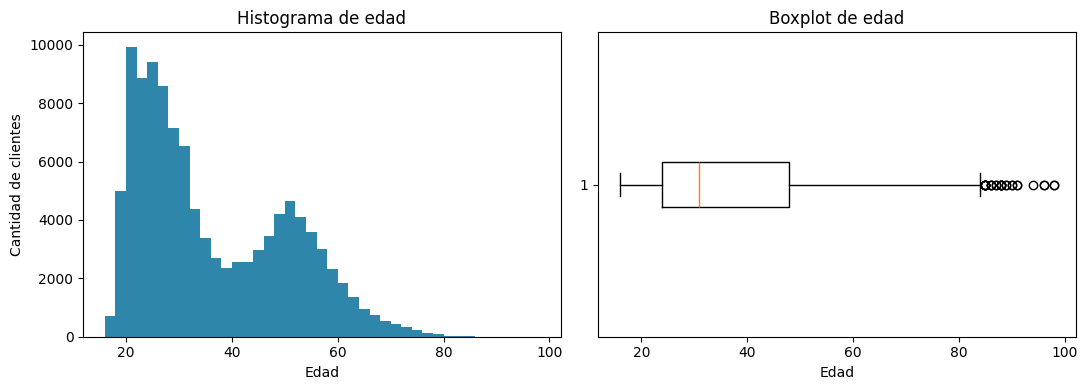

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(edad, bins=range(16, 100, 2), color=AZUL)
ax[0].set_title("Histograma de edad")
ax[0].set_xlabel("Edad")
ax[0].set_ylabel("Cantidad de clientes")
ax[1].boxplot(edad, vert=False)
ax[1].set_title("Boxplot de edad")
ax[1].set_xlabel("Edad")
plt.tight_layout()
plt.show()

In [18]:
n_compras = trans.groupby("customer_id").size().rename("n_trans")
c = cust.merge(n_compras, on="customer_id", how="left")
c["sin_edad"] = c["age"].isna()
display(c.groupby("sin_edad")["n_trans"].describe())

,count,mean,std,min,25%,50%,75%,max
sin_edad,,,,,,,,
False,"109,044.0000",20.3461,37.5676,1.0000,3.0000,8.0000,21.0000,"1,068.0000"
True,"1,208.0000",6.5108,10.2898,1.0000,2.0000,3.0000,7.0000,158.0000


**Conclusión de `age`:** tiene 1.208 vacíos (1,10%). Entre los 109.044 clientes con dato, la edad va de 16 a 98 años, con mediana 31 y promedio 35,9. La distribución se inclina hacia clientes jóvenes (el 25% tiene 24 años o menos, el 50% 31 o menos). El histograma muestra **dos grupos**: uno grande entre los 20 y 30 años y otro más chico alrededor de los 50; el boxplot, al resumir todo en una caja, no deja ver esa forma. La cola hacia edades mayores es gradual: el 95% tiene 61 años o menos y el 99%, 71 o menos. Solo 27 clientes (0,02%) superan los 84 años (7 superan los 90); son edades posibles y no se eliminan. El mínimo de 16 sugiere que el dataset no incluye menores, aunque no está documentado. Los 1.208 clientes sin edad **compran menos** que el resto (mediana de 3 compras contra 8; promedio 6,5 contra 20,3), así que el vacío no parece aleatorio; no se sabe por qué.

**Decisión:** no imputar con la mediana general (mezclaría dos grupos con comportamiento distinto); usar un grupo "sin edad" aparte. Es una foto de un solo momento (ver limitaciones).

### 4.7 `postal_code`

In [19]:
print("Vacíos:", cust["postal_code"].isna().sum(), "| valores distintos:", cust["postal_code"].nunique(), "| largos:", cust["postal_code"].str.len().value_counts().to_dict())
conteo = cust["postal_code"].value_counts()
display(conteo.describe().to_frame("clientes por código"))
display(conteo.head(3).to_frame("clientes"))
print("Códigos con un solo cliente:", (conteo == 1).sum())

Vacíos: 0 | valores distintos: 87652 | largos: {64: 110252}


,clientes por código
count,"87,652.0000"
mean,1.2578
std,9.6633
min,1.0000
25%,1.0000
50%,1.0000
75%,1.0000
max,"2,857.0000"


,clientes
postal_code,
2c29ae653a9282cce4151bd87643c907644e09541abc28ae87dea0d1f6603b1c,2857
45dc52765eb24eb8bc8a4a40a682d5e430aed58a9aba44e7f67d9516e54ba0d1,21
7c1fa3b0ec1d37ce2c3f34f63bd792f3b4494f324b6be5d1e4ba6a75456b96a7,15


Códigos con un solo cliente: 72201


In [20]:
es_dom = (cust["postal_code"] == conteo.index[0]).rename("código dominante")
comp = cust.groupby(es_dom).agg(clientes=("customer_id", "size"),
                                 edad_mediana=("age", "median"),
                                 pct_edad_vacia=("age", lambda s: s.isna().mean() * 100),
                                 pct_FN_vacio=("FN", lambda s: s.isna().mean() * 100))
comp["pct_PRE_CREATE"] = cust.groupby(es_dom)["club_member_status"].apply(lambda s: (s == "PRE-CREATE").mean() * 100)
display(comp.round(1))

,clientes,edad_mediana,pct_edad_vacia,pct_FN_vacio,pct_PRE_CREATE
código dominante,,,,,
False,107395,31.0000,0.9000,66.0000,8.6000
True,2857,29.0000,7.6000,74.3000,0.7000


**Conclusión de `postal_code`:** sin vacíos y todos son hashes de 64 caracteres, así que **no se interpreta como ubicación**. Hay 87.652 valores distintos para 110.252 clientes y el 82% de los códigos tiene un solo cliente. Un único código concentra 2.857 clientes (2,6%), unas 136 veces más que el segundo (21), lo que sugiere un **valor por defecto** para datos faltantes. Esos 2.857 clientes se parecen al resto en edad (mediana 29 contra 31) pero tienen 7,6% de edad vacía (contra 0,9%), más `FN` vacío (74% contra 66%) y casi no tienen PRE-CREATE (0,7% contra 8,6%): es un grupo distinto, coherente con la hipótesis, que sigue sin poder confirmarse por el hash. Por la cantidad de categorías y la falta de significado geográfico, **se conserva pero no se usa como variable**. La propuesta contempla simular un mercado nuevo apartando clientes por código postal, pero con estos datos **no conviene**: el hash no tiene significado geográfico, el 82% de los códigos tiene un solo cliente y el código dominante (2,6% de los clientes) parece "sin dato", así que solo se podrían apartar grupos arbitrarios. La justificación completa va en el README.

<a id="s5"></a>
## 5. Artículos (`art`)

Una fila por artículo. Se revisan nulos, la clave y los identificadores, los valores "Unknown" que funcionan como faltantes, la consistencia entre códigos y nombres y la calidad de las descripciones y categorías.

### 5.1 Estructura y nulos

In [21]:
art.info(show_counts=True)
nulos_art = art.isna().sum()
print(nulos_art[nulos_art > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   article_id                    105542 non-null  object
 1   product_code                  105542 non-null  object
 2   prod_name                     105542 non-null  object
 3   product_type_no               105542 non-null  int64 
 4   product_type_name             105542 non-null  object
 5   product_group_name            105542 non-null  object
 6   graphical_appearance_no       105542 non-null  int64 
 7   graphical_appearance_name     105542 non-null  object
 8   colour_group_code             105542 non-null  object
 9   colour_group_name             105542 non-null  object
 10  perceived_colour_value_id     105542 non-null  int64 
 11  perceived_colour_value_name   105542 non-null  object
 12  perceived_colour_master_id    105542 non-null  int64 
 13 

**Conclusión:** `art` tiene 105.542 filas y 25 columnas (8 numéricas y 17 de texto). Solo `detail_desc` tiene vacíos: 416 (0,39%), sin descripciones vacías como texto. `colour_group_code` (con ceros iniciales, como '01') e `index_code` (letras) son texto.

### 5.2 Clave e identificadores

In [22]:
print("Filas:", len(art))
print("article_id repetidos:", art["article_id"].duplicated().sum())
print("Filas completamente repetidas:", art.duplicated().sum())
print("Largos de article_id:", art["article_id"].str.len().value_counts().to_dict())
print("Largos de product_code:", art["product_code"].str.len().value_counts().to_dict())
print("product_code = primeros 7 dígitos de article_id:", (art["article_id"].str[:7] == art["product_code"]).all())
print("Productos distintos (product_code):", art["product_code"].nunique())
print("Artículos por producto (promedio):", round(len(art) / art["product_code"].nunique(), 2))

Filas: 105542
article_id repetidos: 0


Filas completamente repetidas: 0
Largos de article_id: {10: 105542}
Largos de product_code: {7: 105542}
product_code = primeros 7 dígitos de article_id: True
Productos distintos (product_code): 47224
Artículos por producto (promedio): 2.23


**Conclusión:** `article_id` es una clave sana: sin repetidos ni filas duplicadas, siempre de 10 caracteres. `product_code` son los **primeros 7 dígitos** del `article_id`. Hay 47.224 productos para 105.542 artículos, unos 2,2 artículos por producto (variantes, típicamente de color).

### 5.3 Valores "Unknown" (faltantes escondidos)

In [23]:
print("colour_group_code = -1:", (art["colour_group_code"] == "-1").sum())
display(art.loc[art["colour_group_code"] == "-1", ["colour_group_code", "colour_group_name"]].drop_duplicates())
for col in ["product_group_name", "product_type_name", "garment_group_name", "colour_group_name"]:
    k = (art[col] == "Unknown").sum()
    print(f"{col} = Unknown: {k:,} ({k / len(art):.2%})")

colour_group_code = -1: 28


,colour_group_code,colour_group_name
21238,-1,Unknown


product_group_name = Unknown: 121 (0.11%)
product_type_name = Unknown: 121 (0.11%)
garment_group_name = Unknown: 3,873 (3.67%)
colour_group_name = Unknown: 28 (0.03%)


**Conclusión:** aunque no hay nulos en esas columnas, hay faltantes escondidos como la categoría "Unknown": `garment_group_name` 3.873 artículos (3,67%), `product_group_name` y `product_type_name` 121 (0,11%) y `colour_group_name` 28 (0,03%, con código -1). Se tratan como una categoría más, sin imputar.

### 5.4 Consistencia de pares código / nombre

In [24]:
pares = [("product_type_no", "product_type_name"), ("graphical_appearance_no", "graphical_appearance_name"),
         ("colour_group_code", "colour_group_name"), ("perceived_colour_value_id", "perceived_colour_value_name"),
         ("perceived_colour_master_id", "perceived_colour_master_name"), ("department_no", "department_name"),
         ("index_code", "index_name"), ("index_group_no", "index_group_name"),
         ("section_no", "section_name"), ("garment_group_no", "garment_group_name")]
filas = []
for cod, nom in pares:
    filas.append({"codigo": cod,
                  "codigos_distintos": art[cod].nunique(),
                  "nombres_distintos": art[nom].nunique(),
                  "codigos_con_mas_de_un_nombre": int((art.groupby(cod)[nom].nunique() > 1).sum()),
                  "nombres_con_mas_de_un_codigo": int((art.groupby(nom)[cod].nunique() > 1).sum())})
display(pd.DataFrame(filas))

,codigo,codigos_distintos,nombres_distintos,codigos_con_mas_de_un_nombre,nombres_con_mas_de_un_codigo
0,product_type_no,132,131,0,1
1,graphical_appearance_no,30,30,0,0
2,colour_group_code,50,50,0,0
3,perceived_colour_value_id,8,8,0,0
4,perceived_colour_master_id,20,20,0,0
5,department_no,299,250,0,22
6,index_code,10,10,0,0
7,index_group_no,5,5,0,0
8,section_no,57,56,0,1
9,garment_group_no,21,21,0,0


**Conclusión:** en los 10 pares ningún código tiene más de un nombre, así que los códigos son consistentes. Al revés sí pasa en 3 pares: `department_name` (22 nombres con más de un código: 299 códigos para 250 nombres), `product_type_name` (1) y `section_name` (1). No es un error, pero para agrupar conviene usar el código y no el nombre.

### 5.5 Descripción y categorías

In [25]:
d = art["detail_desc"]
print(d.str.len().describe().round(1).to_string())
print("Descripciones repetidas (entre las que existen):", d.dropna().duplicated().sum())
res = art.groupby("product_group_name")["detail_desc"].agg(total="size", nulos=lambda s: s.isna().sum())
res["pct"] = (res["nulos"] / res["total"] * 100).round(2)
display(res[res["nulos"] > 0].sort_values("nulos", ascending=False))
for col in ["index_group_name", "product_group_name"]:
    display(art[col].value_counts().to_frame("articulos"))
for col in ["prod_name", "product_type_name", "colour_group_name", "department_name", "section_name"]:
    s = art[col]
    print(f"{col}: espacios en los bordes = {(s != s.str.strip()).sum()}, espacios dobles = {s.str.contains('  ').sum()}")

count   105,126.0000
mean        142.2000
std          68.1000
min          11.0000
25%          94.0000
50%         132.0000
75%         178.0000
max         764.0000
Descripciones repetidas (entre las que existen): 61722


,total,nulos,pct
product_group_name,,,
Garment Upper body,42741,148,0.3500
Shoes,5283,87,1.6500
Garment Lower body,19812,49,0.2500
Garment Full body,13292,47,0.3500
Underwear,5490,41,0.7500
Swimwear,3127,23,0.7400
Accessories,11158,17,0.1500
Socks & Tights,2442,4,0.1600


,articulos
index_group_name,
Ladieswear,39737
Baby/Children,34711
Divided,15149
Menswear,12553
Sport,3392


,articulos
product_group_name,
Garment Upper body,42741
Garment Lower body,19812
Garment Full body,13292
Accessories,11158
Underwear,5490
Shoes,5283
Swimwear,3127
Socks & Tights,2442
Nightwear,1899


prod_name: espacios en los bordes = 0, espacios dobles = 517
product_type_name: espacios en los bordes = 0, espacios dobles = 0
colour_group_name: espacios en los bordes = 0, espacios dobles = 0
department_name: espacios en los bordes = 0, espacios dobles = 0
section_name: espacios en los bordes = 0, espacios dobles = 0


**Conclusión:** la descripción mide en promedio 142 caracteres (mínimo 11, máximo 764). Hay 61.722 descripciones repetidas, esperable porque las variantes de un producto la comparten. Los 416 vacíos están sobre todo en prendas de arriba (148) y calzado (87). Las categorías están bien escritas, sin espacios de más en los bordes. Los grupos grandes son prendas de arriba (42.741), de abajo (19.812) y de cuerpo entero (13.292); `index_group_name` lo domina Ladieswear (39.737), seguido de Baby/Children (34.711). Hay grupos muy chicos que no son ropa (Cosmetic 49, Bags 25, Items 17, Furniture 13...). Solo `prod_name` tiene 517 nombres con espacios dobles: menor, no se corrige. Se conserva todo; para un recomendador por contenido se puede completar la descripción con tipo, color y grupo.

<a id="s6"></a>
## 6. Integridad entre tablas

Se verifica que todos los clientes y artículos de las compras existan en sus tablas maestras (integridad referencial) y cuántos artículos del catálogo no tienen ventas.

In [26]:
cli_trans, cli_cust = set(trans["customer_id"]), set(cust["customer_id"])
art_trans, art_art = set(trans["article_id"]), set(art["article_id"])
print("Clientes de trans que no están en cust:", len(cli_trans - cli_cust))
print("Clientes de cust sin ninguna compra:", len(cli_cust - cli_trans))
print("Artículos de trans que no están en art:", len(art_trans - art_art))
sin_venta = len(art_art - art_trans)
print(f"Artículos del catálogo sin ninguna venta en la muestra: {sin_venta:,} ({sin_venta / len(art_art):.1%})")

Clientes de trans que no están en cust: 0
Clientes de cust sin ninguna compra: 0
Artículos de trans que no están en art: 0
Artículos del catálogo sin ninguna venta en la muestra: 27,224 (25.8%)


**Conclusión:** la integridad es completa: todos los clientes y artículos de `trans` existen en sus tablas y todos los clientes de `cust` compraron al menos una vez. El 25,8% del catálogo (27.224 artículos) no tiene ventas **en la muestra**; como la muestra es el 10% de los clientes, ese porcentaje está inflado respecto del dataset completo. Cualquier cifra por artículo se ve afectada por esto; las cifras por cliente no, porque de cada cliente elegido se conserva todo su historial.

<a id="s7"></a>
## 7. Corte train/test

La partición es **temporal, nunca al azar**: el test son los **últimos 7 días completos**. Esa regla coincide con el esquema de evaluación original del dataset (test = 7 días posteriores al fin de los datos, la misma semana para todos). El último día del dataset es el 22/9/2020, así que el test va del 16 al 22/9/2020 y el train llega hasta el 15/9. **Es la partición adoptada por el grupo.**

In [27]:
ULTIMO_DIA = trans["t_dat"].max()
CORTE = ULTIMO_DIA - pd.Timedelta(days=6)
train = trans[trans["t_dat"] < CORTE]
test = trans[trans["t_dat"] >= CORTE]
print(f"Test : {CORTE.date()} a {ULTIMO_DIA.date()} (7 días)")
print(f"Train: hasta {(CORTE - pd.Timedelta(days=1)).date()}")
print(f"Train: {len(train):>10,} compras ({len(train) / len(trans):.1%}) | clientes: {train['customer_id'].nunique():,}")
print(f"Test : {len(test):>10,} compras ({len(test) / len(trans):.1%}) | clientes: {test['customer_id'].nunique():,}")
cola = diario.tail(14).to_frame("compras")
cola["dia_semana"] = cola.index.day_name()
cola["vs_promedio_previo"] = (cola["compras"] / diario.iloc[-42:-14].mean()).round(2)
display(cola)

Test : 2020-09-16 a 2020-09-22 (7 días)
Train: hasta 2020-09-15


Train:  2,210,154 compras (99.3%) | clientes: 109,815
Test :     16,332 compras (0.7%) | clientes: 4,162


,compras,dia_semana,vs_promedio_previo
t_dat,,,
2020-09-09,3005,Wednesday,1.1900
2020-09-10,2703,Thursday,1.0700
2020-09-11,2368,Friday,0.9300
2020-09-12,2058,Saturday,0.8100
2020-09-13,3316,Sunday,1.3100
2020-09-14,2072,Monday,0.8200
2020-09-15,1997,Tuesday,0.7900
2020-09-16,1877,Wednesday,0.7400
2020-09-17,2816,Thursday,1.1100


**Conclusión:** train = 2.210.154 compras (99,3%) y test = 16.332 (0,7%) de 4.162 clientes. Los últimos 14 días quedan entre 0,74 y 1,31 veces el nivel de las 4 semanas previas, sin ningún día extremo, así que la semana de test es comparable. A partir de acá, **todo lo que se use para decidir algo sale solo de `train`**.

# PARTE 2. Exploración con train

Desde acá se trabaja **solo con train** (compras hasta el 15/9/2020), para que ninguna decisión use información del futuro. La excepción son los duplicados (sección 11), que se identifican en la tabla completa porque son un control de calidad.

<a id="s8"></a>
## 8. Evolución temporal

Se describe la actividad por mes y por día de la semana para detectar estacionalidad, meses atípicos y períodos incompletos.

,compras,clientes,dias,compras_por_dia
mes,,,,
2018-09,36910,7637,11,"3,355.0000"
2018-10,96660,16847,31,"3,118.0000"
2018-11,90560,17976,30,"3,019.0000"
2018-12,69814,14494,31,"2,252.0000"
2019-01,93126,16019,31,"3,004.0000"
2019-02,76477,13526,28,"2,731.0000"
2019-03,90961,15158,31,"2,934.0000"
2019-04,102357,16151,30,"3,412.0000"
2019-05,106493,16458,31,"3,435.0000"


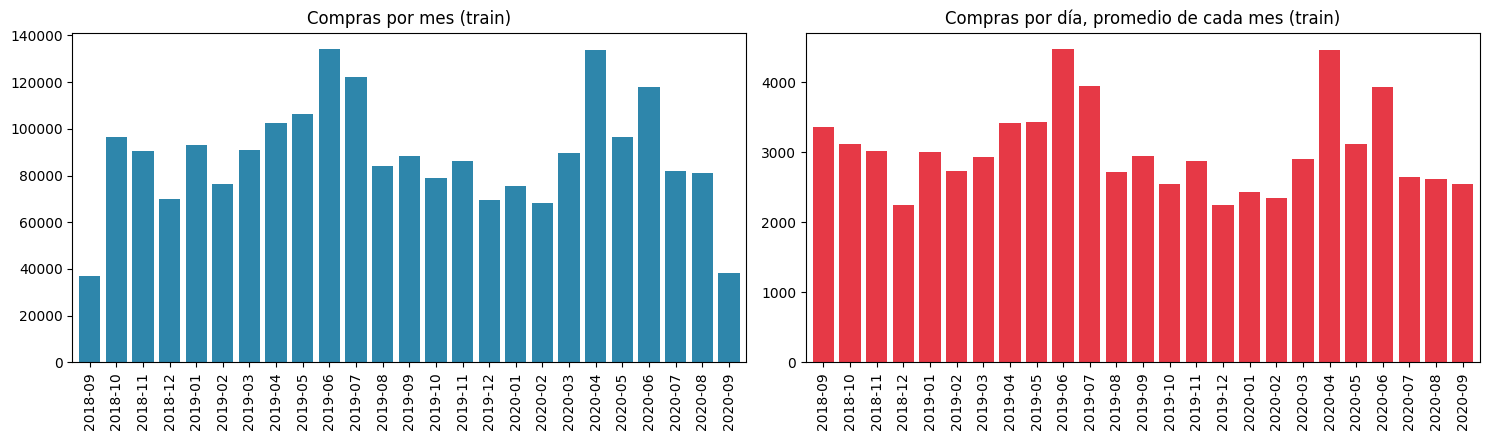

,% de las compras
Lunes,13.9000
Martes,13.9000
Miércoles,16.1000
Jueves,14.9000
Viernes,13.5000
Sábado,13.5000
Domingo,14.1000


In [28]:
mensual = train.assign(mes=train["t_dat"].dt.to_period("M")).groupby("mes").agg(
    compras=("article_id", "size"), clientes=("customer_id", "nunique"), dias=("t_dat", "nunique"))
mensual["compras_por_dia"] = (mensual["compras"] / mensual["dias"]).round(0)
display(mensual)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
mensual["compras"].plot(kind="bar", ax=ax[0], color=AZUL, width=0.8)
ax[0].set_title("Compras por mes (train)"); ax[0].set_xlabel("")
mensual["compras_por_dia"].plot(kind="bar", ax=ax[1], color=ROJO, width=0.8)
ax[1].set_title("Compras por día, promedio de cada mes (train)"); ax[1].set_xlabel("")
plt.tight_layout()
plt.show()

dias_es = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
semana = train.groupby(train["t_dat"].dt.dayofweek).size()
semana.index = dias_es
display((semana / semana.sum() * 100).round(1).to_frame("% de las compras"))

**Conclusión:** septiembre de 2018 (11 días) y septiembre de 2020 (15 días en train) están incompletos en días, **no en ritmo** (3.355 y 2.552 compras por día, dentro de lo normal). Los picos de ritmo diario son junio de 2019 (4.480 por día) y abril de 2020 (4.459 por día); diciembre es el mes más bajo (unas 2.250 por día). Abril de 2020 coincide con el cierre de tiendas de la pandemia (otros análisis del dataset lo señalan como atípico; es una hipótesis, el dataset no lo dice), y se lo evaluó junto con marzo y mayo de 2020; **decisión del grupo: se conservan en el entrenamiento** (ver `reports/tratamiento_datos.csv`). Por día de la semana el miércoles es el más alto (16,1%) y viernes y sábado los más bajos (13,5%); el resto queda entre 13,9% y 14,9%.

<a id="s9"></a>
## 9. Estacionalidad y hemisferio

Se mira cómo cambia durante el año el peso de algunas categorías para inferir el hemisferio de los datos, ya que el proveedor de los datos no revela el mercado.

,Swimwear (ropa de baño),Knitwear (punto),Outdoor
ene,8.3000,9.7000,3.2000
feb,9.6000,6.1000,2.8000
mar,9.2000,4.7000,2.6000
abr,12.7000,2.4000,1.4000
may,17.6000,2.0000,1.1000
jun,16.3000,1.6000,0.7000
jul,15.6000,1.8000,0.9000
ago,10.3000,5.5000,1.9000
sep,2.2000,13.6000,3.9000
oct,2.6000,14.3000,4.5000


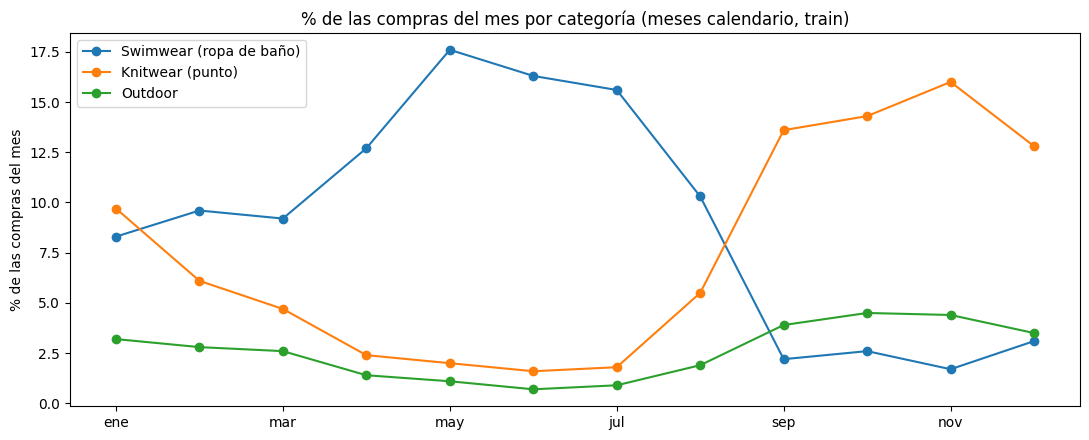

In [29]:
cols = ["article_id", "product_group_name", "garment_group_name", "index_group_name", "product_type_name"]
ta = train.merge(art[cols], on="article_id", how="left")
ta["mes_n"] = ta["t_dat"].dt.month
tot_mes = ta.groupby("mes_n").size()
est = pd.DataFrame({
    "Swimwear (ropa de baño)": ta[ta["product_group_name"] == "Swimwear"].groupby("mes_n").size() / tot_mes * 100,
    "Knitwear (punto)": ta[ta["garment_group_name"] == "Knitwear"].groupby("mes_n").size() / tot_mes * 100,
    "Outdoor": ta[ta["garment_group_name"] == "Outdoor"].groupby("mes_n").size() / tot_mes * 100,
}).round(1)
est.index = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
display(est)
est.plot(figsize=(11, 4.5), marker="o")
plt.title("% de las compras del mes por categoría (meses calendario, train)")
plt.ylabel("% de las compras del mes")
plt.tight_layout()
plt.show()

**Conclusión:** la ropa de baño pesa 17,6% de las compras en mayo, 16,3% en junio y 15,6% en julio, contra 1,7% en noviembre y 2,2% en septiembre; el punto (`Knitwear`) va al revés: 16,0% en noviembre, 14,3% en octubre y 13,6% en septiembre, contra 1,6% en junio y 2,0% en mayo. Es el patrón del **hemisferio norte**, invertido respecto de Argentina. Esto sale de los datos (el proveedor de los datos no revela el mercado): indica el hemisferio, **no el país**. Se mira como proporción del total del mes para que las liquidaciones o los picos de ventas no distorsionen. Para usar el recomendador en Argentina, la estacionalidad debería invertirse o ignorarse (limitación).

<a id="s10"></a>
## 10. Precio por tipo de producto

Se busca a qué tipos de producto corresponde la cola alta del precio y si el precio depende del tipo. Es el pendiente que había quedado para el cruce de `trans` con `art`.

Compras en el 0,1% de precios más altos (>= 0.1749): 2,230


,compras
product_type_name,
Coat,527
Jacket,505
Dress,465
Sweater,277
Trousers,114
Boots,107
Blazer,99
Cardigan,30


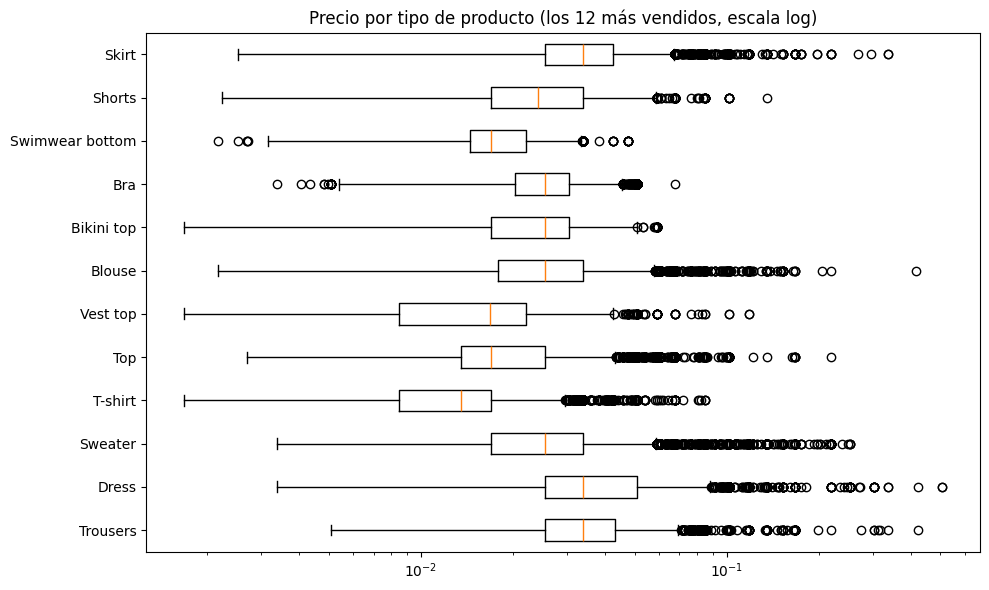

,count,median
product_type_name,,
Coat,9416,0.0949
Jacket,45784,0.0678
Boots,15239,0.0542
Blazer,30075,0.0508
Swimsuit,23940,0.0424


,count,median
product_type_name,,
Socks,15996,0.0135
T-shirt,137320,0.0135
Necklace,5542,0.0131


In [30]:
umbral = train["price"].quantile(0.999)
top = ta[ta["price"] >= umbral]
print(f"Compras en el 0,1% de precios más altos (>= {umbral:.4f}): {len(top):,}")
display(top["product_type_name"].value_counts().head(8).to_frame("compras"))

tipos = ta["product_type_name"].value_counts().head(12).index.tolist()
datos = []
for t in tipos:
    p = ta.loc[ta["product_type_name"] == t, "price"]
    datos.append(p.sample(min(20000, len(p)), random_state=1))
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(datos, vert=False)
ax.set_yticks(range(1, len(tipos) + 1))
ax.set_yticklabels(tipos)
ax.set_xscale("log")
ax.set_title("Precio por tipo de producto (los 12 más vendidos, escala log)")
plt.tight_layout()
plt.show()

med = ta.groupby("product_type_name")["price"].agg(["count", "median"])
med = med[med["count"] > 5000].sort_values("median", ascending=False)
display(med.head(5))
display(med.tail(3))

**Conclusión:** la cola alta del precio no son errores: el 0,1% más caro (2.230 compras) son sobre todo abrigos (527) y camperas (505), vestidos (465) y suéteres (277). La mediana por tipo lo confirma: Coat 0,0949, Jacket 0,0678 y Boots 0,0542, contra 0,0135 de T-shirt y Socks. **El precio depende del tipo de producto**, por lo que no se compara entre tipos distintos ni se eliminan los valores altos.

<a id="s11"></a>
## 11. Duplicados por grupo de producto

Se mira en qué grupos de producto se concentran las filas repetidas de `trans` (sección 3.5) para acotar las explicaciones posibles.

In [31]:
tg = trans.assign(dup=trans.duplicated()).merge(art[["article_id", "product_group_name"]], on="article_id", how="left")
dd = tg.groupby("product_group_name")["dup"].agg(compras="size", pct_repetidas="mean")
dd["pct_repetidas"] = (dd["pct_repetidas"] * 100).round(1)
display(dd.sort_values("compras", ascending=False).head(10))
del tg
k = trans.groupby(["t_dat", "customer_id", "article_id"])["price"].nunique()
print("Combinaciones día-cliente-artículo con más de un precio:", (k > 1).sum())
del k

,compras,pct_repetidas
product_group_name,,
Garment Upper body,840088,10.6000
Garment Lower body,522087,13.9000
Garment Full body,282518,11.8000
Swimwear,215874,16.8000
Underwear,167379,11.4000
Accessories,78431,5.6000
Shoes,62496,8.4000
Nightwear,25508,9.1000
Socks & Tights,24097,14.7000


Combinaciones día-cliente-artículo con más de un precio: 17082


**Conclusión:** los duplicados aparecen en **todos** los grupos: ropa de baño 16,8%, medias y pantys 14,7%, prendas de abajo 13,9%, prendas de cuerpo entero 11,8%, de arriba 10,6%, calzado 8,4% y accesorios 5,6%. Son más bajos en los accesorios (que no tienen talle), pero no son cero, así que **no alcanza para decidir** entre "varias unidades", "distintos talles" o "compra y devolución" y puede ser una mezcla. **Decisión del grupo:** se conservan, porque no hay evidencia de error y representan más demanda (ver `reports/tratamiento_datos.csv`).

<a id="s12"></a>
## 12. Compras por cliente

Se describe cuántas compras tiene cada cliente en train. Es la base para decidir cómo simular clientes fríos (con poco historial).

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
compras por cliente,"109,815.0000",20.1262,37.2208,1.0000,1.0000,3.0000,7.0000,21.0000,51.0000,180.0000,"1,068.0000"


Una sola compra: 12,385 (11.3%) | 5 o menos: 45,940 (41.8%)


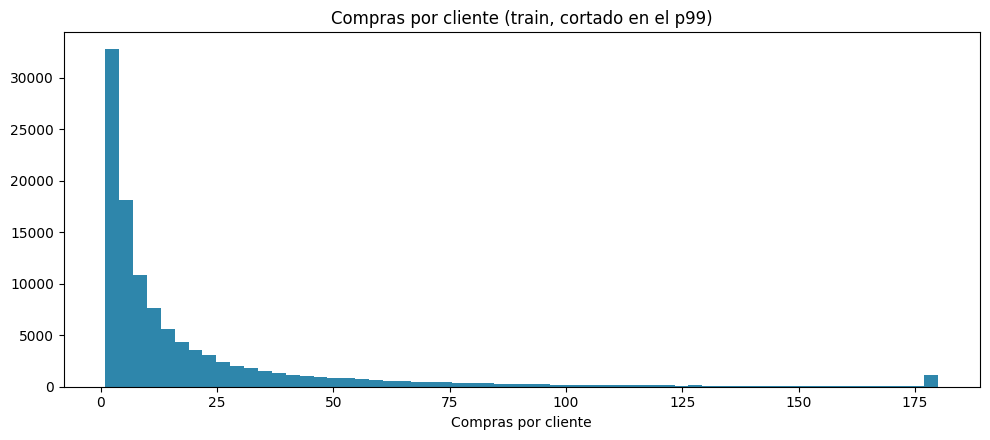

In [32]:
compras_cli = train.groupby("customer_id").size()
display(compras_cli.describe(percentiles=[.1, .25, .5, .75, .9, .99]).to_frame("compras por cliente").T)
print(f"Una sola compra: {(compras_cli == 1).sum():,} ({(compras_cli == 1).mean():.1%}) | 5 o menos: {(compras_cli <= 5).sum():,} ({(compras_cli <= 5).mean():.1%})")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(compras_cli.clip(upper=compras_cli.quantile(0.99)), bins=60, color=AZUL)
ax.set_title("Compras por cliente (train, cortado en el p99)")
ax.set_xlabel("Compras por cliente")
plt.tight_layout()
plt.show()

**Conclusión:** en train hay 109.815 clientes con compras (los otros 437 solo compran en el test). Mediana de 7 compras, promedio 20,1, p90 51, p99 180 y máximo 1.068. El 11,3% tiene una sola compra y el 41,8% tiene 5 o menos: **hay muchos clientes con muy poco historial**, lo que favorece simular clientes fríos ocultando parte del historial.

<a id="s13"></a>
## 13. Artículos y cola larga

Se mide la concentración de las ventas y cuántos artículos casi no se venden. Es la referencia para el baseline de popularidad.

Artículos con ventas en train: 77,780 | sin ventas: 27,762 (26.3%)
Artículos con una sola venta: 11,591 (14.9% de los vendidos)
Top    12 artículos =   1.1% de las ventas
Top   100 artículos =   4.6% de las ventas
Top 1,000 artículos =  18.9% de las ventas
Top 5,000 artículos =  44.8% de las ventas
Artículos para cubrir el 50% de las ventas: 6290


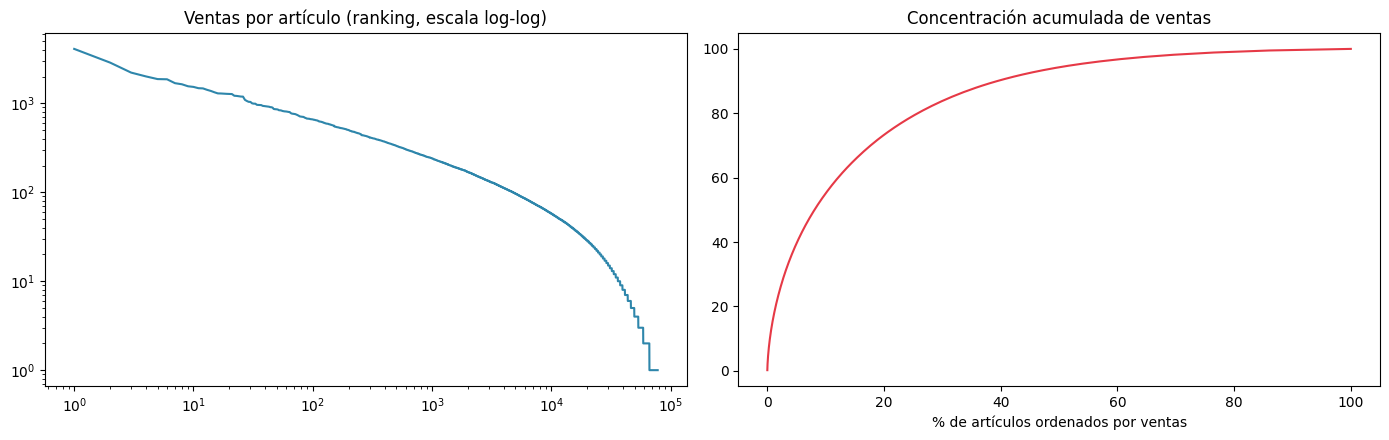

In [33]:
ventas = train["article_id"].value_counts()
acum = ventas.cumsum() / ventas.sum()
print(f"Artículos con ventas en train: {len(ventas):,} | sin ventas: {len(art) - len(ventas):,} ({(len(art) - len(ventas)) / len(art):.1%})")
print(f"Artículos con una sola venta: {(ventas == 1).sum():,} ({(ventas == 1).mean():.1%} de los vendidos)")
for k in [12, 100, 1000, 5000]:
    print(f"Top {k:>5,} artículos = {acum.iloc[k - 1] * 100:5.1f}% de las ventas")
print("Artículos para cubrir el 50% de las ventas:", int((acum < 0.5).sum() + 1))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].loglog(np.arange(1, len(ventas) + 1), ventas.values, color=AZUL)
ax[0].set_title("Ventas por artículo (ranking, escala log-log)")
ax[1].plot(np.arange(1, len(acum) + 1) / len(acum) * 100, acum.values * 100, color=ROJO)
ax[1].set_title("Concentración acumulada de ventas")
ax[1].set_xlabel("% de artículos ordenados por ventas")
plt.tight_layout()
plt.show()

**Conclusión:** la cola es muy larga: los 12 artículos más vendidos suman solo 1,1% de las ventas, los 1.000 primeros 18,9% y hacen falta 6.290 artículos para cubrir la mitad. 11.591 artículos (14,9% de los vendidos) se vendieron una sola vez, y 27.762 (26,3% del catálogo) no tienen ventas en train, aunque en la muestra del 10% esos números están inflados (sección 6). Un recomendador de "lo más vendido" tiene mucho margen de mejora y va a necesitar **atributos del artículo**, no solo su historial.

<a id="s14"></a>
## 14. Edad y mix de compra

Se cruza la edad del cliente con el grupo de índice de lo que compra, para ver si la edad es una señal útil cuando no hay historial.

index_group_name,Baby/Children,Divided,Ladieswear,Menswear,Sport
tramo_edad,,,,,
<=20,1.0000,36.8000,56.5000,3.1000,2.5000
21-25,0.9000,29.3000,63.1000,3.2000,3.6000
26-30,1.4000,24.1000,66.5000,3.6000,4.4000
31-40,6.1000,21.1000,65.1000,3.7000,4.1000
41-50,7.5000,22.9000,59.9000,5.8000,3.9000
51-60,2.2000,21.5000,66.0000,6.7000,3.6000
>60,2.7000,18.6000,71.2000,5.2000,2.3000


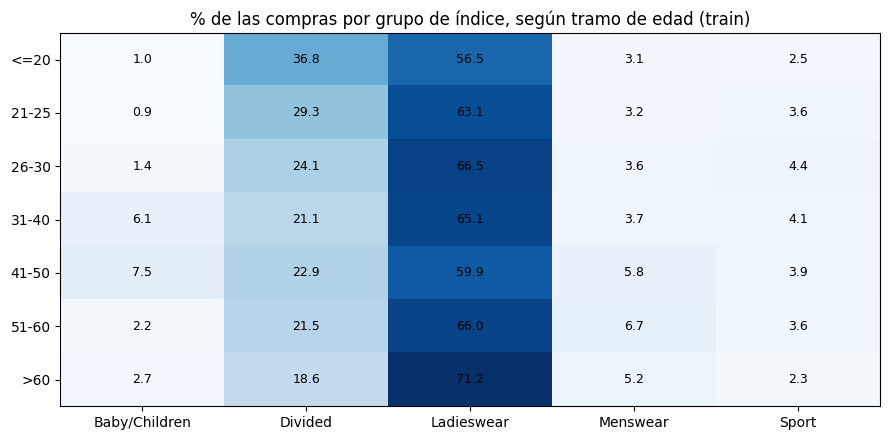

In [34]:
tc = ta.merge(cust[["customer_id", "age"]], on="customer_id", how="left")
tc["tramo_edad"] = pd.cut(tc["age"], bins=[0, 20, 25, 30, 40, 50, 60, 120], labels=["<=20", "21-25", "26-30", "31-40", "41-50", "51-60", ">60"])
mix = pd.crosstab(tc["tramo_edad"], tc["index_group_name"], normalize="index") * 100
display(mix.round(1))
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(mix.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(mix.shape[1])); ax.set_xticklabels(mix.columns)
ax.set_yticks(range(mix.shape[0])); ax.set_yticklabels(mix.index)
for i in range(mix.shape[0]):
    for j in range(mix.shape[1]):
        ax.text(j, i, f"{mix.values[i, j]:.1f}", ha="center", va="center", fontsize=9)
ax.set_title("% de las compras por grupo de índice, según tramo de edad (train)")
plt.tight_layout()
plt.show()
del tc

**Conclusión:** el mix de compra cambia con la edad. Divided (línea joven) pesa 36,8% entre los de 20 años o menos y baja a 18,6% después de los 60; Ladieswear sube de 56,5% a 71,2%; Menswear sube de 3,1% a 6,7% (entre los 51 y 60 años); y Baby/Children se concentra entre los 31 y 50 años (6,1% y 7,5%), seguramente compras para hijos. La edad es una **señal útil para clientes fríos** con perfil conocido (hipótesis a probar en el modelo). Ladieswear domina en todos los tramos.

<a id="s15"></a>
## 15. Clientes fríos y cobertura de artículos

Se cuantifica cuántos clientes del test son fríos naturales (sin compras en train) y qué proporción de los artículos del test no aparece en train. Estas cifras condicionan cómo se evalúa el recomendador.

In [35]:
clientes_train, clientes_test = set(train["customer_id"]), set(test["customer_id"])
frios = clientes_test - clientes_train
print(f"Clientes que compran en test: {len(clientes_test):,}")
print(f"  con historial en train: {len(clientes_test & clientes_train):,}")
print(f"  fríos naturales (sin compras en train): {len(frios):,} ({len(frios) / len(clientes_test):.1%})")
t_frios = test["customer_id"].isin(frios).sum()
print(f"Compras del test de fríos naturales: {t_frios:,} ({t_frios / len(test):.1%} del test)")

arts_train, arts_test = set(train["article_id"]), set(test["article_id"])
aus = arts_test - arts_train
aus_t = (~test["article_id"].isin(arts_train)).sum()
print(f"Artículos distintos comprados en test: {len(arts_test):,} | ausentes en train: {len(aus):,} ({len(aus) / len(arts_test):.1%})")
print(f"Compras del test sobre artículos ausentes en train: {aus_t:,} ({aus_t / len(test):.1%})")
top12 = train["article_id"].value_counts().head(12).index
print(f"Peso de los 12 más vendidos de train en el test: {test['article_id'].isin(top12).mean():.2%}")

perfil = cust[cust["customer_id"].isin(clientes_test)].copy()
perfil["tipo"] = np.where(perfil["customer_id"].isin(frios), "frío natural", "con historial")
display(perfil.groupby("tipo")["age"].describe().round(1))
display((pd.crosstab(perfil["tipo"], perfil["club_member_status"], normalize="index") * 100).round(1))
pre = perfil["club_member_status"] == "PRE-CREATE"
n_pre_frio = (pre & (perfil["tipo"] == "frío natural")).sum()
print(f"PRE-CREATE en el test: {pre.sum()} | fríos entre ellos: {n_pre_frio} ({n_pre_frio / pre.sum():.1%}) | cubren el {n_pre_frio / len(frios):.1%} de los fríos")

Clientes que compran en test: 4,162
  con historial en train: 3,725
  fríos naturales (sin compras en train): 437 (10.5%)
Compras del test de fríos naturales: 1,442 (8.8% del test)
Artículos distintos comprados en test: 4,778 | ausentes en train: 538 (11.3%)
Compras del test sobre artículos ausentes en train: 1,537 (9.4%)
Peso de los 12 más vendidos de train en el test: 0.92%


,count,mean,std,min,25%,50%,75%,max
tipo,,,,,,,,
con historial,"3,718.0000",36.1000,13.9000,17.0000,24.0000,31.0000,49.0000,94.0000
frío natural,437.0000,34.3000,14.6000,17.0000,22.0000,29.0000,48.0000,75.0000


club_member_status,ACTIVE,LEFT CLUB,PRE-CREATE
tipo,,,
con historial,98.6000,0.0000,1.4000
frío natural,93.8000,0.2000,6.0000


PRE-CREATE en el test: 77 | fríos entre ellos: 26 (33.8%) | cubren el 5.9% de los fríos


**Conclusión:** en el test compran 4.162 clientes y solo **437 son fríos naturales** (10,5%; 1.442 compras, 8,8% del test). Son pocos para evaluar un modelo, lo que justifica **sumar fríos simulados** (ocultar parte del historial de clientes con compras). Se parecen en edad (mediana 29 contra 31), pero son más seguido socios PRE-CREATE (6,0% contra 1,4%), pero como detector de clientes fríos es débil: de los 77 clientes PRE-CREATE del test solo 26 son fríos (33,8%, contra 10,5% en general) y esos 26 cubren apenas el 5,9% de los fríos (ver la advertencia de *leakage* de la sección 4.4). Además, 538 de los 4.778 artículos del test (11,3%; 9,4% de las compras) no aparecen en train, y los 12 más vendidos de train solo cubren el 0,92% de las compras del test: un baseline de "lo más vendido" parte **débil**, y se necesitan atributos del artículo para los artículos nuevos. Las cifras por cliente son confiables; las por artículo están afectadas por el muestreo del 10%.

<a id="s16"></a>
# Hallazgos, decisiones y limitaciones

In [36]:
resumen = pd.Series({
    "Compras (filas)": f"{len(trans):,}",
    "Clientes": f"{len(cust):,}",
    "Artículos en el catálogo": f"{len(art):,}",
    "Rango de fechas": f"{trans['t_dat'].min().date()} a {trans['t_dat'].max().date()}",
    "Filas repetidas (%)": f"{trans.duplicated().mean() * 100:.2f}",
    "Edad vacía (%)": f"{cust['age'].isna().mean() * 100:.2f}",
    "Clientes con una sola compra en train (%)": f"{(compras_cli == 1).mean() * 100:.1f}",
    "Primer día del test (corte provisorio)": f"{CORTE.date()}",
    "Clientes fríos naturales en el test (%)": f"{len(frios) / len(clientes_test) * 100:.1f}",
    "Artículos del test ausentes en train (%)": f"{len(aus) / len(arts_test) * 100:.1f}",
    "Peso del top 12 de train en el test (%)": f"{test['article_id'].isin(top12).mean() * 100:.2f}",
}, name="valor")
display(resumen.to_frame())

,valor
Compras (filas),"2,226,486"
Clientes,"110,252"
Artículos en el catálogo,"105,542"
Rango de fechas,2018-09-20 a 2020-09-22
Filas repetidas (%),11.96
Edad vacía (%),1.10
Clientes con una sola compra en train (%),11.3
Primer día del test (corte provisorio),2020-09-16
Clientes fríos naturales en el test (%),10.5
Artículos del test ausentes en train (%),11.3


**Hallazgos principales**
- Datos limpios: sin nulos en `trans`, claves sanas, integridad completa entre tablas y 734 días sin huecos. Los vacíos están en `FN`, `Active` (~66%), `age` (1,1%) y `detail_desc` (0,4%).
- `FN`, `Active` y `postal_code` se conservan pero no se usan como variables; `Active` no se puede interpretar y `postal_code` tiene un código dominante que parece un valor por defecto.
- La edad es la única variable de cliente que se conserva y se plantea como hipótesis a probar en los clientes fríos (dos grupos de edad y mix de compra distinto), con el cuidado de que `cust` es una foto de un solo momento. El resultado de la prueba está en `docs/README_modelado.md`.
- Estacionalidad de hemisferio norte; abril de 2020 atípico.
- Cola larga muy marcada y solo 437 fríos naturales: hace falta simular fríos, y el baseline de "más vendidos" es débil.

**Decisiones tomadas (del grupo)**
- Corte temporal: train hasta el 15/9/2020 y test del 16 al 22/9/2020 (7 días).
- Marzo a mayo de 2020: se conservan en el entrenamiento.
- Duplicados: se conservan (misma prenda, cliente y día).
- Edad vacía: no se imputa; forman el grupo "sin edad".
- `PRE-CREATE` y el resto de las variables de cliente: no se usan; solo se usa la edad.
- Fríos: se simulan ocultando el historial (0, 1 o 2 compras visibles), con resultados en `docs/README_modelado.md`.

**Limitaciones a declarar**
- Mercado desconocido; el hemisferio norte se infiere de la estacionalidad (invertida respecto de Argentina).
- Precio sin unidad; no hay talle ni cantidad; la tabla incluye devoluciones; la fecha no tiene hora.
- `cust` es una foto de un solo momento: `Active`, `FN`, `club_member_status` y `age` pueden reflejar al cliente después de su primera compra (*leakage*), un riesgo relevante para los fríos.
- Evaluación *offline*: los datos solo registran compras, no qué vio cada cliente (sesgo de exposición); el top 12 del baseline parte de ese sesgo.
- La muestra es el 10% de los clientes: las cifras por artículo están infladas; las por cliente no.
- No se trabaja con imágenes.